In [111]:
import h5py
import numpy as np
from scipy.interpolate import griddata

import matplotlib.pyplot as plt

#Set fonts
from matplotlib import rc, rcParams, cm
rc('font', **{'family': 'sans-serif', 'sans-serif': ['Arial']})
#Use tex for math
rcParams['mathtext.fontset'] = 'cm'
rcParams['text.latex.preamble'] = r"\usepackage{amsmath}"

In [112]:
# Functions for plotting 

def PlotLine(y = 2*56.25/25.4, x = 1.5*56.25/25.4, dpi=100):
	fig, ax = plt.subplots(figsize=(y, x), dpi=dpi, tight_layout=True)
	return ax

### Read input data

In [113]:
FName = "400_1000s_f2"

fileName = FName + ".diff.in.hdf5"

with h5py.File(fileName, "r") as fh5:
	nSteps = fh5["SimulationParameters"]["nSteps"][()]   

### Read results

In [134]:
Time = np.zeros(nSteps)
AvCon = np.zeros(nSteps)
AvTrapCon = np.zeros(nSteps)

FName = "300_1000s_f4_k1_dis"
fileName = FName + ".diff.out.hdf5"

with h5py.File(fileName, "r") as fh5:
	
	for iStep in range(nSteps):
		Time[iStep] = fh5["Time"]["Step_"+str(iStep)][()][0]
		AvCon[iStep] = fh5["AvCon"]["Step_"+str(iStep)][()][0]
		AvTrapCon[iStep] = fh5["AvTrapCon"]["Step_"+str(iStep)][()][0]


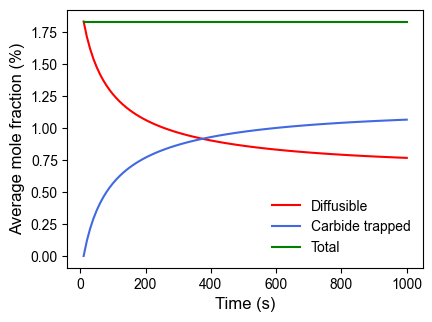

In [135]:
# Plot average concentration

ax = PlotLine()

ax.plot(Time, AvCon*100, lw=1.5, color="r", label="Diffusible")
ax.plot(Time, AvTrapCon*100, lw=1.5, color="royalblue", label="Carbide trapped")
ax.plot(Time, (AvCon+AvTrapCon)*100, lw=1.5, color="green", label="Total")

ax.legend(frameon=False)

ax.set_xlabel("Time (s)", fontsize=12)
ax.set_ylabel("Average mole fraction (%)", fontsize=12)

# ax.set_ylim([0,1])

plt.savefig(FName+"_AvCon.svg")

In [141]:
carbide_ratio = AvTrapCon/(AvCon+AvTrapCon)

In [142]:
carbide_ratio[-1]*100

np.float64(58.15482082424691)

In [139]:
AvTrapCon[-1]

np.float64(0.01065977865707749)

In [140]:
AvTrapCon[-1]

np.float64(0.01065977865707749)

In [48]:
AvCon[-1]

np.float64(0.007735665495427874)

In [54]:
data_400_f2 = np.loadtxt("400_f2.csv", skiprows=1, delimiter=",")
data_400_f3 = np.loadtxt("400_f3.csv", skiprows=1, delimiter=",")
data_400_f4 = np.loadtxt("400_f4.csv", skiprows=1, delimiter=",")

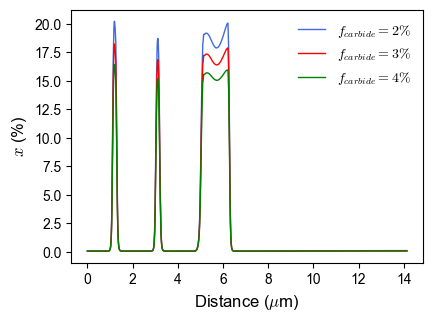

In [63]:
ax = PlotLine()

ax.plot(data_400_f2[:,4]*1e3, data_400_f2[:,0]*100, lw=1, color="royalblue", label="$f_{carbide} = 2 \\%$")
ax.plot(data_400_f3[:,4]*1e3, data_400_f3[:,0]*100, lw=1, color="r", label="$f_{carbide} = 3 \\%$")
ax.plot(data_400_f4[:,4]*1e3, data_400_f4[:,0]*100, lw=1, color="green", label="$f_{carbide} = 4 \\%$")

ax.set_xlabel("Distance ($\\mu$m)", fontsize=12)
ax.set_ylabel("$x$ (%)", fontsize=12)

ax.legend(frameon=False)

plt.savefig("400_diff_line.svg")

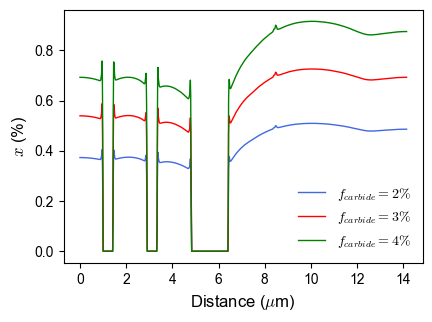

In [64]:
ax = PlotLine()

ax.plot(data_400_f2[:,4]*1e3, data_400_f2[:,2]*100, lw=1, color="royalblue", label="$f_{carbide} = 2 \\%$")
ax.plot(data_400_f3[:,4]*1e3, data_400_f3[:,2]*100, lw=1, color="r", label="$f_{carbide} = 3 \\%$")
ax.plot(data_400_f4[:,4]*1e3, data_400_f4[:,2]*100, lw=1, color="green", label="$f_{carbide} = 4 \\%$")

ax.set_xlabel("Distance ($\\mu$m)", fontsize=12)
ax.set_ylabel("$x$ (%)", fontsize=12)

ax.legend(frameon=False)

plt.savefig("400_trap_line.svg")

In [105]:
data_300 = np.loadtxt("300_eq.csv", skiprows=1, delimiter=",")
data_400 = np.loadtxt("400_eq.csv", skiprows=1, delimiter=",")

<>:7: SyntaxWarning: invalid escape sequence '\%'
<>:7: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_35578/2394164242.py:7: SyntaxWarning: invalid escape sequence '\%'
  ax.set_ylabel("$x (\%)$", fontsize=12)


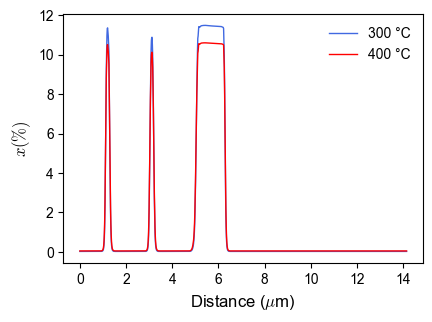

In [110]:
ax = PlotLine()

ax.plot(data_300[:,3]*1e3, data_300[:,0]*100, lw=1, color="royalblue", label=str(300)+" °C")
ax.plot(data_400[:,3]*1e3, data_400[:,0]*100, lw=1, color="r", label=str(400)+" °C")

ax.set_xlabel("Distance ($\\mu$m)", fontsize=12)
ax.set_ylabel("$x (\%)$", fontsize=12)

ax.legend(frameon=False)

plt.savefig("eq_diff_line.svg")

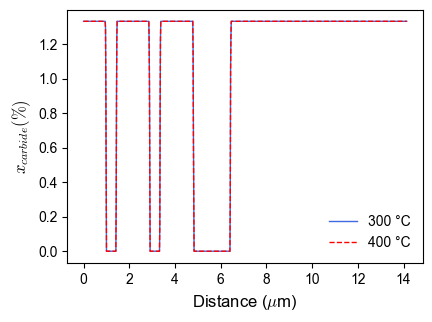

In [109]:
ax = PlotLine()

ax.plot(data_300[:,3]*1e3, data_300[:,1]*100, lw=1, color="royalblue", label=str(300)+" °C")
ax.plot(data_400[:,3]*1e3, data_400[:,1]*100, lw=1, ls='--', color="r", label=str(400)+" °C")

ax.set_xlabel("Distance ($\\mu$m)", fontsize=12)
ax.set_ylabel("$x_{carbide} (\\%)$", fontsize=12)

ax.legend(frameon=False)

plt.savefig("eq_trap_line.svg")